# Phân tích dữ liệu OSM khu Vinhomes Ocean Park 1 (OCP1)

| Mục | Nội dung | Phần trong `task.md` |
|------|----------|---------------------|
| 0 | Chuẩn bị: nạp dữ liệu vào bộ nhớ | |
| 1 | Đếm node, way, relation | 2.1 |
| 2 | Node dùng chung từ 2 way `highway` trở lên | 2.2 |
| 3 | Relation `multipolygon` có tag `building` | 2.3 |
| 4 | Way có `layer`, `bridge` hoặc `tunnel` | 2.4 |
| 5 | Building có `building:levels`, `height` | 2.5 |
| 6 | Thống kê giá trị tag (cho báo cáo LT3) | LT3 |
| 7 | Tổng hợp kết quả | |

**Dữ liệu:** `data/ocp1.osm.pbf` (cắt từ Geofabrik Việt Nam 2026-11-04 theo bbox OCP1). Way chạm bbox được giữ nguyên nên có node nằm ngoài bbox; các bản đồ bên dưới chỉ vẽ trong bbox.


> **Input:** `data/ocp1.osm.pbf`. Trên Colab: tạo thư mục `data` trong `/content`, upload file vào đó.

## 0. Chuẩn bị

Khai báo thư viện, đường dẫn

Cài `osmium` (cần khi chạy trên Colab).

In [ ]:
%pip install -q osmium

In [1]:
from collections import Counter, defaultdict
from pathlib import Path
import re

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import osmium
import pandas as pd
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D

PBF = Path("data/ocp1.osm.pbf")
OUT = Path("output/nb")
FIG = Path("output/figures")
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

BBOX = (105.9334479, 20.9840728, 105.9628773, 21.0047847)
ASPECT = 1 / np.cos(np.radians(21.0))

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, PALE = "#0b0b0b", "#52514e", "#e6e5e1", "#c9c8c2"

mpl.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "text.color": INK,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
    "axes.labelcolor": MUTED,
    "axes.edgecolor": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "legend.frameon": False,
})
pd.options.display.max_colwidth = 70

print(PBF, f"{PBF.stat().st_size / 1024:.0f} KB")

data/ocp1.osm.pbf 256 KB


In [2]:
def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")


def way_coords(way):
    return [nodes[ref] for ref in way["refs"] if ref in nodes]


def new_map(figsize=(8.5, 7)):
    fig, ax = plt.subplots(figsize=figsize)
    return fig, ax


def draw_ways(ax, way_ids, color, linewidth=0.8, alpha=1.0, zorder=2):
    lines = [way_coords(ways[w]) for w in way_ids]
    ax.add_collection(LineCollection(lines, colors=color, linewidths=linewidth, alpha=alpha, zorder=zorder))


def finish_map(ax, title):
    ax.set_xlim(BBOX[0], BBOX[2])
    ax.set_ylim(BBOX[1], BBOX[3])
    ax.set_aspect(ASPECT)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)


def bar_labels(ax, bars, values, fmt="{:,}"):
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], padding=3, color=INK, fontsize=9)

### Nạp dữ liệu vào bộ nhớ

Đọc file PBF **một lượt** bằng `osmium.FileProcessor`, giữ lại ba cấu trúc để các bước sau dùng chung:

| Biến | Kiểu | Nội dung |
|------|------|----------|
| `nodes` | `dict` id → `(lon, lat)` | tọa độ mọi node |
| `node_tags` | `dict` id → `dict` | tag của các node có tag |
| `ways` | `dict` id → `{"refs", "tags"}` | danh sách id node và tag của way |
| `relations` | `dict` id → `{"members", "tags"}` | member `(loại, id, role)` và tag của relation |

Lưu ý: đối tượng mà `FileProcessor` trả về chỉ hợp lệ trong lúc duyệt, nên code **copy** dữ liệu ra dict thay vì giữ chính đối tượng.

In [3]:
nodes = {}
node_tags = {}
ways = {}
relations = {}

for obj in osmium.FileProcessor(PBF):
    if obj.is_node():
        nodes[obj.id] = (obj.location.lon, obj.location.lat)
        if len(obj.tags):
            node_tags[obj.id] = dict(obj.tags)
    elif obj.is_way():
        ways[obj.id] = {"refs": [n.ref for n in obj.nodes], "tags": dict(obj.tags)}
    else:
        relations[obj.id] = {
            "members": [(m.type, m.ref, m.role) for m in obj.members],
            "tags": dict(obj.tags),
        }

print(f"node={len(nodes):,}  way={len(ways):,}  relation={len(relations):,}")

node=31,117  way=3,951  relation=89


## 1. Đếm node, way, relation (phần 2.1 của `task.md`)

**Mục tiêu:** biết quy mô dữ liệu.

**Cách làm:** lấy độ dài của ba dict ở trên; tính tỉ lệ và số phần tử có tag.

In [4]:
counts = pd.DataFrame({
    "số lượng": [len(nodes), len(ways), len(relations)],
    "có tag": [len(node_tags), sum(1 for w in ways.values() if w["tags"]), sum(1 for r in relations.values() if r["tags"])],
}, index=["node", "way", "relation"])
counts["tỉ lệ có tag"] = (counts["có tag"] / counts["số lượng"]).map("{:.1%}".format)
counts.loc["tổng"] = [counts["số lượng"].sum(), counts["có tag"].sum(), ""]
counts

,số lượng,có tag,tỉ lệ có tag
node,31117,4472,14.4%
way,3951,3914,99.1%
relation,89,89,100.0%
tổng,35157,8475,


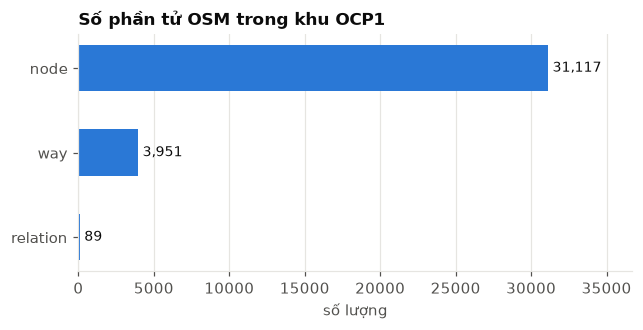

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 2.8))
labels = ["node", "way", "relation"]
values = counts.loc[labels, "số lượng"].tolist()
bars = ax.barh(labels[::-1], values[::-1], color=BLUE, height=0.55)
bar_labels(ax, bars, values[::-1])
ax.set_xlim(0, max(values) * 1.18)
ax.set_title("Số phần tử OSM trong khu OCP1")
ax.set_xlabel("số lượng")
ax.grid(axis="y", visible=False)
save(fig, "2_1_element_counts.png")
plt.show()

**Đọc kết quả:** node chiếm phần lớn (khoảng 88%) nhưng chỉ khoảng 14% node có tag; còn lại là điểm hình học của way. Relation rất ít (89) nhưng mỗi relation đều có tag.

## 2. Node dùng chung từ 2 way `highway` trở lên (phần 2.2 của `task.md`)

**Mục tiêu:** tìm giao lộ và điểm nối của mạng đường (xem LT1.2 trong `report/theory.md`).

**Cách làm:**
1. Lọc các way có tag `highway`.
2. Với mỗi way, mỗi node id chỉ tính **một lần** (dùng `set`; way khép kín lặp node đầu và cuối).
3. Gom: `node id → tập id các way highway chứa nó`.
4. Giữ node có từ 2 way trở lên.

**Đầu vào:** `ways`. **Đầu ra:** bảng `shared_df`, ghi ra `output/nb/shared_nodes.csv`.

In [6]:
highway_ways = {wid: w for wid, w in ways.items() if "highway" in w["tags"]}

ways_per_node = defaultdict(set)
for wid, way in highway_ways.items():
    for ref in way["refs"]:
        ways_per_node[ref].add(wid)

shared = {ref: wids for ref, wids in ways_per_node.items() if len(wids) >= 2}

print(f"way highway: {len(highway_ways):,}")
print(f"node thuộc way highway: {len(ways_per_node):,}")
print(f"node dùng chung từ 2 way trở lên: {len(shared):,}")

way highway: 1,960
node thuộc way highway: 11,666
node dùng chung từ 2 way trở lên: 3,621


In [7]:
shared_df = pd.DataFrame([
    {
        "node_id": ref,
        "lat": nodes[ref][1],
        "lon": nodes[ref][0],
        "way_count": len(wids),
        "way_ids": " ".join(map(str, sorted(wids))),
        "highway_types": " ".join(sorted({highway_ways[w]["tags"]["highway"] for w in wids})),
    }
    for ref, wids in shared.items()
]).sort_values(["way_count", "node_id"], ascending=[False, True]).reset_index(drop=True)

shared_df.to_csv(OUT / "shared_nodes.csv", index=False)
shared_df.head(10)

,node_id,lat,lon,way_count,way_ids,highway_types
0,9196948608,20.986978,105.944721,6,995998800 995998803 995998804 995998805 995998806 995998807,footway
1,2516235789,20.985039,105.943228,5,601487487 601543277 1138100056 1138100057 1177226278,secondary tertiary
2,5719032864,20.986994,105.941697,5,1149187590 1177226278 1227330215 1243387903 1493442123,motorway_link secondary secondary_link
3,7119403206,20.992217,105.960689,5,854837630 957184371 1014224395 1014224397 1359074582,residential tertiary
4,7119403371,20.987197,105.941505,5,601883834 777888664 957454494 957454500 1243387903,secondary
5,7262861395,20.996087,105.939940,5,761986878 778191216 1226458542 1341471463 1341471464,residential
6,7262861396,20.997452,105.940840,5,761986878 1087927575 1194927099 1560647124 1560647125,residential service
7,7972661312,20.991094,105.946214,5,854837613 854837627 1484464573 1484464574 1493442131,residential service tertiary tertiary_link
8,8730634772,20.988211,105.942068,5,896414895 957454494 957454496 957454501 1224486134,residential secondary secondary_link
9,5633643103,21.002114,105.934427,4,589969540 589969542 589969543 1119201307,footway


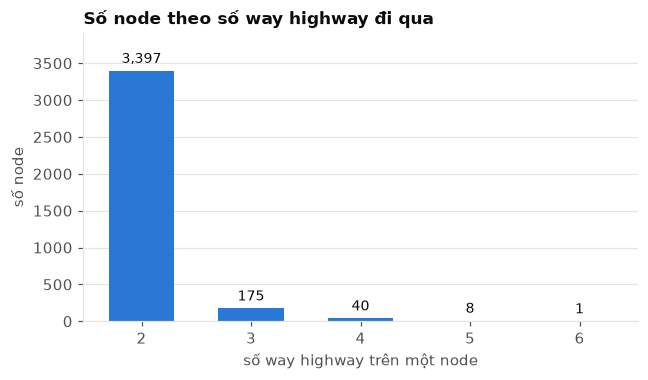

In [8]:
dist = shared_df["way_count"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6.5, 3.4))
bars = ax.bar(dist.index.astype(str), dist.values, color=BLUE, width=0.6)
bar_labels(ax, bars, dist.values)
ax.set_ylim(0, dist.max() * 1.15)
ax.set_title("Số node theo số way highway đi qua")
ax.set_xlabel("số way highway trên một node")
ax.set_ylabel("số node")
ax.grid(axis="x", visible=False)
save(fig, "2_2_shared_node_distribution.png")
plt.show()

**Đọc kết quả:** phần lớn node dùng chung chỉ có đúng 2 way (điểm nối hai đoạn đường hoặc ngã ba đơn giản); số node có 4 way trở lên (ngã tư, ngã năm) rất ít.

Bản đồ dưới đặt các node đó lên mạng đường để thấy chúng nằm ở đâu: đường vẽ xám, node dùng chung 2 đến 3 way xanh dương, node từ 4 way trở lên cam.

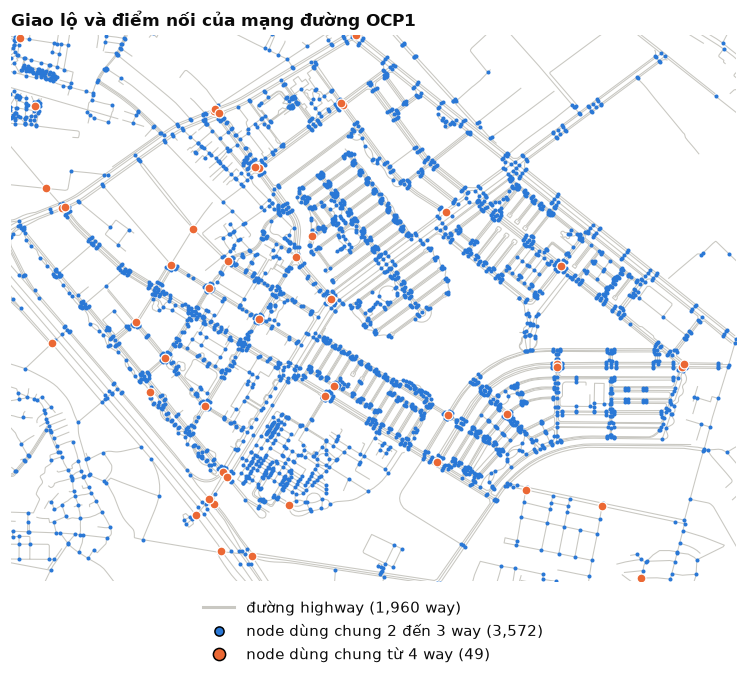

In [9]:
fig, ax = new_map()
draw_ways(ax, highway_ways, PALE, linewidth=0.7)

few = shared_df[shared_df["way_count"] < 4]
many = shared_df[shared_df["way_count"] >= 4]
ax.scatter(few["lon"], few["lat"], s=7, color=BLUE, zorder=3, linewidths=0)
ax.scatter(many["lon"], many["lat"], s=34, color=ORANGE, edgecolors="white", linewidths=0.8, zorder=4)

handles = [
    Line2D([0], [0], color=PALE, lw=2, label=f"đường highway ({len(highway_ways):,} way)"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=BLUE, markersize=6, label=f"node dùng chung 2 đến 3 way ({len(few):,})"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=ORANGE, markersize=8, label=f"node dùng chung từ 4 way ({len(many):,})"),
]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=1)
finish_map(ax, "Giao lộ và điểm nối của mạng đường OCP1")
save(fig, "2_2_shared_nodes_map.png")
plt.show()

## 3. Relation `multipolygon` có tag `building` (phần 2.3 của `task.md`)

**Mục tiêu:** liệt kê các tòa nhà được mô tả bằng relation (xem LT1.5).

**Cách làm:**
1. Lọc relation có `type=multipolygon` **và** có tag `building` (tag của tòa nhà nằm trên relation, không nằm trên các way thành viên).
2. Đếm member theo vai trò: `outer` (vòng ngoài) và `inner` (lỗ, ví dụ sân trong).

**Đầu ra:** bảng `mp_df`, ghi ra `output/nb/mp_buildings.csv`.

In [10]:
mp_buildings = {
    rid: r for rid, r in relations.items()
    if r["tags"].get("type") == "multipolygon" and "building" in r["tags"]
}

rows = []
for rid, r in mp_buildings.items():
    roles = Counter((mtype, role) for mtype, ref, role in r["members"])
    rows.append({
        "relation_id": rid,
        "building": r["tags"]["building"],
        "name": r["tags"].get("name", ""),
        "building_levels": r["tags"].get("building:levels", ""),
        "height": r["tags"].get("height", ""),
        "outer": roles[("w", "outer")],
        "inner": roles[("w", "inner")],
        "members": len(r["members"]),
    })

mp_df = pd.DataFrame(rows)
mp_df.to_csv(OUT / "mp_buildings.csv", index=False)
mp_df

,relation_id,building,name,building_levels,height,outer,inner,members
0,16676566,school,,,,1,4,5
1,16676568,school,,,,1,6,7


Hai relation này đều là trường học. Biểu đồ dưới vẽ chính hình học của chúng: **vòng ngoài** tô xanh, **lỗ bên trong** (các `inner`) để trống. Đây là cách một multipolygon biểu diễn "tòa nhà có sân trong".

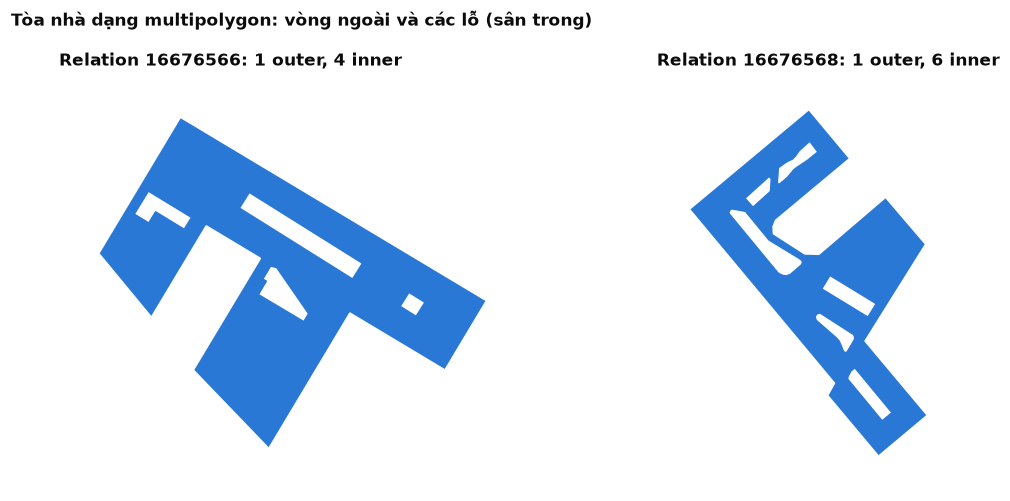

In [11]:
def ring(way_id):
    return way_coords(ways[way_id])


fig, axes = plt.subplots(1, len(mp_buildings), figsize=(10, 4.6))
axes = np.atleast_1d(axes)

for ax, (rid, r) in zip(axes, mp_buildings.items()):
    outers = [ring(ref) for t, ref, role in r["members"] if role == "outer"]
    inners = [ring(ref) for t, ref, role in r["members"] if role == "inner"]
    ax.add_collection(PolyCollection(outers, facecolors=BLUE, edgecolors="white", linewidths=1.2, zorder=2))
    ax.add_collection(PolyCollection(inners, facecolors="white", edgecolors=BLUE, linewidths=1.0, zorder=3))
    xs = [x for poly in outers for x, y in poly]
    ys = [y for poly in outers for x, y in poly]
    pad = 0.00015
    ax.set_xlim(min(xs) - pad, max(xs) + pad)
    ax.set_ylim(min(ys) - pad, max(ys) + pad)
    ax.set_aspect(ASPECT)
    ax.set_title(f"Relation {rid}: {len(outers)} outer, {len(inners)} inner")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle("Tòa nhà dạng multipolygon: vòng ngoài và các lỗ (sân trong)", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
save(fig, "2_3_multipolygon_buildings.png")
plt.show()

Để thấy hai relation này nhỏ thế nào trong tổng thể, đếm **tất cả** multipolygon theo loại đối tượng chúng mô tả.

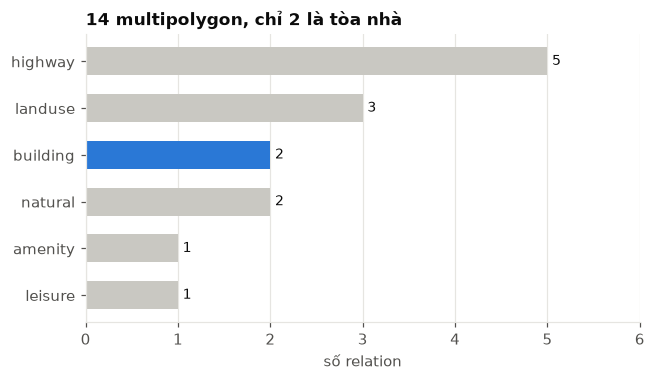

In [12]:
PRIORITY = ["building", "amenity", "landuse", "natural", "leisure", "highway"]


def mp_class(tags):
    for key in PRIORITY:
        if key in tags:
            return key
    return "khác"


all_mp = {rid: r for rid, r in relations.items() if r["tags"].get("type") == "multipolygon"}
mp_kinds = pd.Series(Counter(mp_class(r["tags"]) for r in all_mp.values())).sort_values()

fig, ax = plt.subplots(figsize=(6.5, 3.4))
colors = [BLUE if k == "building" else PALE for k in mp_kinds.index]
bars = ax.barh(mp_kinds.index, mp_kinds.values, color=colors, height=0.6)
bar_labels(ax, bars, mp_kinds.values)
ax.set_xlim(0, mp_kinds.max() * 1.2)
ax.set_title(f"{len(all_mp)} multipolygon, chỉ {mp_kinds.get('building', 0)} là tòa nhà")
ax.set_xlabel("số relation")
ax.grid(axis="y", visible=False)
save(fig, "2_3_multipolygon_by_kind.png")
plt.show()

**Đọc kết quả:** multipolygon trong dữ liệu chủ yếu mô tả vùng khác (đất, nước, lối đi), không phải tòa nhà. Vì vậy phải lọc theo tag `building`, không chỉ theo `type=multipolygon`.

## 4. Way có `layer`, `bridge` hoặc `tunnel` (phần 2.4 của `task.md`)

**Mục tiêu:** tìm các đối tượng có quan hệ chiều dọc với đối tượng khác (xem LT1.3 và LT3.4).

**Cách làm:** lọc way có ít nhất một trong ba tag, rồi gán nhãn `kind`:
- `bridge`: có tag `bridge`
- `tunnel`: có tag `tunnel`
- `chỉ layer`: có `layer` nhưng không có `bridge` hay `tunnel`

**Đầu ra:** bảng `lbt_df`, ghi ra `output/nb/layer_bridge_tunnel.csv`.

In [13]:
KEYS = ("layer", "bridge", "tunnel")

lbt_rows = []
for wid, way in ways.items():
    tags = way["tags"]
    if not any(k in tags for k in KEYS):
        continue
    lbt_rows.append({
        "way_id": wid,
        "highway": tags.get("highway", ""),
        "layer": tags.get("layer", ""),
        "bridge": tags.get("bridge", ""),
        "tunnel": tags.get("tunnel", ""),
        "name": tags.get("name", ""),
        "node_count": len(way["refs"]),
    })

lbt_df = pd.DataFrame(lbt_rows)
lbt_df["kind"] = np.select(
    [lbt_df["bridge"] != "", lbt_df["tunnel"] != ""],
    ["bridge", "tunnel"],
    default="chỉ layer",
)
lbt_df.drop(columns="kind").to_csv(OUT / "layer_bridge_tunnel.csv", index=False)

print(f"way có layer, bridge hoặc tunnel: {len(lbt_df)}")
pd.crosstab(lbt_df["kind"], lbt_df["layer"].replace("", "không có"), margins=True, margins_name="tổng")

way có layer, bridge hoặc tunnel: 36


layer,-1,1,2,tổng
kind,,,,
bridge,0,14,5,19
chỉ layer,7,4,1,12
tunnel,5,0,0,5
tổng,12,18,6,36


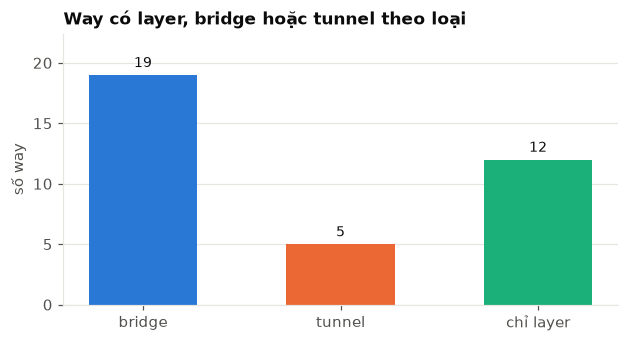

In [14]:
kind_colors = {"bridge": BLUE, "tunnel": ORANGE, "chỉ layer": AQUA}
kind_counts = lbt_df["kind"].value_counts().reindex(["bridge", "tunnel", "chỉ layer"])

fig, ax = plt.subplots(figsize=(6.5, 3.2))
bars = ax.bar(kind_counts.index, kind_counts.values, color=[kind_colors[k] for k in kind_counts.index], width=0.55)
bar_labels(ax, bars, kind_counts.values)
ax.set_ylim(0, kind_counts.max() * 1.18)
ax.set_title("Way có layer, bridge hoặc tunnel theo loại")
ax.set_ylabel("số way")
ax.grid(axis="x", visible=False)
save(fig, "2_4_layer_bridge_tunnel_counts.png")
plt.show()

Bản đồ dưới đặt các way này lên mạng đường. Màu giống biểu đồ cột: cầu xanh dương, hầm cam, "chỉ layer" xanh ngọc. Một số cầu và hầm nằm sát hoặc ngoài mép bản đồ vì chúng thuộc way chạm bbox.

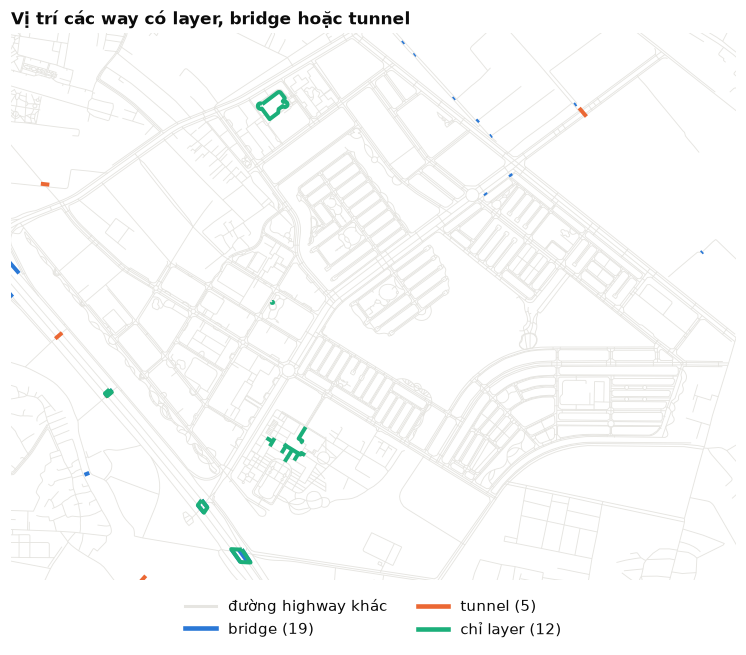

In [15]:
fig, ax = new_map()
draw_ways(ax, highway_ways, GRID, linewidth=0.6, zorder=1)

for kind, color in kind_colors.items():
    ids = lbt_df.loc[lbt_df["kind"] == kind, "way_id"]
    draw_ways(ax, ids, color, linewidth=2.6, zorder=3)

handles = [Line2D([0], [0], color=c, lw=3, label=f"{k} ({(lbt_df['kind'] == k).sum()})") for k, c in kind_colors.items()]
handles.insert(0, Line2D([0], [0], color=GRID, lw=2, label="đường highway khác"))
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2)
finish_map(ax, "Vị trí các way có layer, bridge hoặc tunnel")
save(fig, "2_4_layer_bridge_tunnel_map.png")
plt.show()

**Đọc kết quả:** cầu và hầm chiếm phần lớn nhưng vẫn có way chỉ có `layer` (không kèm `bridge` hay `tunnel`), ví dụ đường đi bộ có `layer=-1` hoặc nhà để xe nhiều tầng. Vì vậy không thể suy ra "cầu hầm" chỉ từ `layer`.

## 5. Building có `building:levels` hoặc `height` (phần 2.5 của `task.md`)

**Mục tiêu:** liệt kê tòa nhà có thông tin số tầng hoặc chiều cao (xem LT3.5 và LT3.6).

**Cách làm:**
1. Lấy mọi way **và** relation có tag `building` và (`building:levels` hoặc `height`).
2. Chuyển giá trị chữ sang số bằng `to_number` (nhận `18`, `18 m`, `18.5`; không nhận `4m` hay `0,8` theo đúng lưu ý của wiki; giá trị lạ thành `NaN`).

**Đầu ra:** bảng `bh_df`, ghi ra `output/nb/building_levels_height.csv`.

In [16]:
NUMBER = re.compile(r"^\s*(\d+(?:\.\d+)?)\s*(?:m|meter|metre|meters|metres)?\s*$", re.IGNORECASE)


def to_number(text):
    if text is None:
        return np.nan
    match = NUMBER.match(text)
    return float(match.group(1)) if match else np.nan


bh_rows = []
for osm_type, store in (("way", ways), ("relation", relations)):
    for oid, obj in store.items():
        tags = obj["tags"]
        if "building" in tags and ("building:levels" in tags or "height" in tags):
            bh_rows.append({
                "osm_type": osm_type,
                "osm_id": oid,
                "building": tags["building"],
                "name": tags.get("name", ""),
                "building_levels": tags.get("building:levels"),
                "levels_num": to_number(tags.get("building:levels")),
                "height": tags.get("height"),
                "height_m": to_number(tags.get("height")),
            })

bh_df = pd.DataFrame(bh_rows)
bh_df.to_csv(OUT / "building_levels_height.csv", index=False)

summary = pd.Series({
    "tổng building": len(bh_df),
    "có building:levels": bh_df["building_levels"].notna().sum(),
    "có height": bh_df["height"].notna().sum(),
    "có cả hai": (bh_df["building_levels"].notna() & bh_df["height"].notna()).sum(),
    "levels không đọc được thành số": (bh_df["building_levels"].notna() & bh_df["levels_num"].isna()).sum(),
    "height không đọc được thành số": (bh_df["height"].notna() & bh_df["height_m"].isna()).sum(),
}, name="số lượng")
summary.to_frame()

,số lượng
tổng building,99
có building:levels,85
có height,14
có cả hai,0
levels không đọc được thành số,0
height không đọc được thành số,0


In [17]:
bh_df.head(8)

,osm_type,osm_id,building,name,building_levels,levels_num,height,height_m
0,way,530485741,yes,Giảng đường C,2,2.0,NaN,NaN
1,way,589659626,roof,Bãi gửi xe sau B4,NaN,NaN,3,3.0
2,way,589837833,roof,Sân Văn Hóa Sinh Viên,NaN,NaN,12,12.0
3,way,589837834,yes,Kí túc xá C5,NaN,NaN,21,21.0
4,way,589837835,yes,Kí túc xá C4,NaN,NaN,21,21.0
5,way,589837836,yes,Kí túc xá C3,NaN,NaN,21,21.0
6,way,589837837,yes,Kí túc xá lưu học sinh,NaN,NaN,15,15.0
7,way,589837838,yes,Kí túc xá C2,NaN,NaN,15,15.0


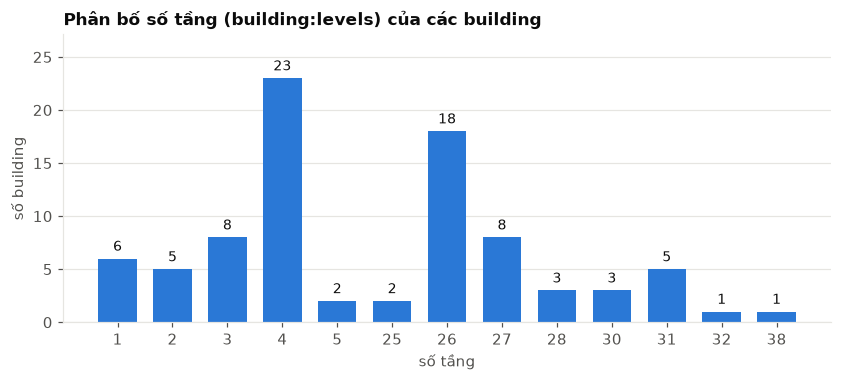

In [18]:
levels_dist = bh_df["levels_num"].dropna().astype(int).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.bar(levels_dist.index.astype(str), levels_dist.values, color=BLUE, width=0.7)
bar_labels(ax, bars, levels_dist.values)
ax.set_ylim(0, levels_dist.max() * 1.18)
ax.set_title("Phân bố số tầng (building:levels) của các building")
ax.set_xlabel("số tầng")
ax.set_ylabel("số building")
ax.grid(axis="x", visible=False)
save(fig, "2_5_levels_distribution.png")
plt.show()

Bản đồ dưới tô các building theo số tầng (xanh càng đậm càng nhiều tầng; xám nhạt là building không có `building:levels`). Hai building dạng multipolygon ở mục 3 không được vẽ ở đây vì tag `building` nằm trên relation, không nằm trên các way vòng ngoài.

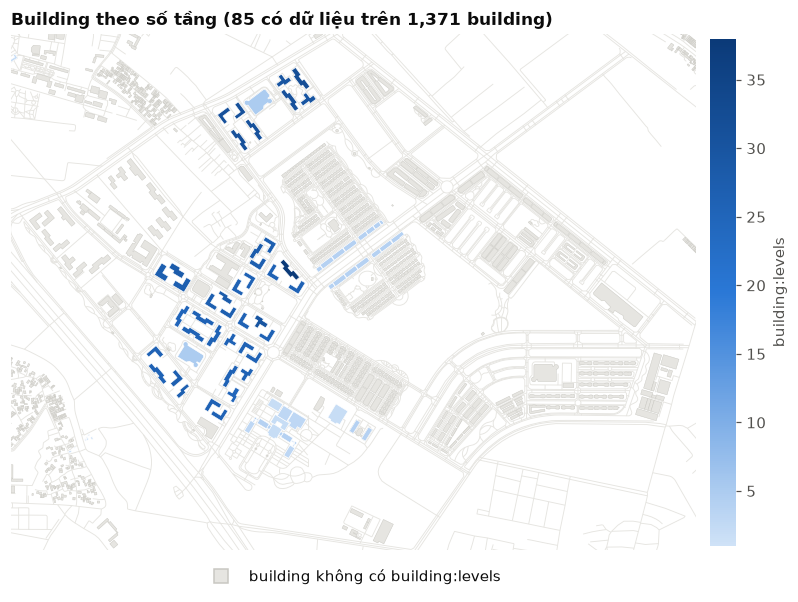

In [19]:
building_ways = {wid: w for wid, w in ways.items() if "building" in w["tags"]}
polys, levels = [], []
for wid, w in building_ways.items():
    polys.append(way_coords(w))
    levels.append(to_number(w["tags"].get("building:levels")))
levels = np.array(levels)
has_levels = ~np.isnan(levels)

cmap = LinearSegmentedColormap.from_list("blues", ["#cfe2f7", BLUE, "#0b3a78"])
norm = Normalize(vmin=1, vmax=np.nanmax(levels))

fig, ax = new_map()
draw_ways(ax, highway_ways, GRID, linewidth=0.6, zorder=1)
gray = [p for p, h in zip(polys, has_levels) if not h]
colored = [p for p, h in zip(polys, has_levels) if h]
ax.add_collection(PolyCollection(gray, facecolors=GRID, edgecolors=PALE, linewidths=0.3, zorder=2))
pc = PolyCollection(colored, array=levels[has_levels], cmap=cmap, norm=norm, edgecolors="white", linewidths=0.4, zorder=3)
ax.add_collection(pc)
ax.legend(handles=[Line2D([0], [0], marker="s", color="none", markerfacecolor=GRID, markeredgecolor=PALE, markersize=9, label="building không có building:levels")],
          loc="upper center", bbox_to_anchor=(0.5, -0.01))
cbar = fig.colorbar(pc, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("building:levels")
cbar.outline.set_visible(False)
finish_map(ax, f"Building theo số tầng ({has_levels.sum()} có dữ liệu trên {len(polys):,} building)")
save(fig, "2_5_levels_map.png")
plt.show()

Kiểm tra mối quan hệ giữa **số tầng** và **chiều cao**. Wiki lấy mặc định 3 m mỗi tầng. Biểu đồ dưới gồm mọi way có **cả hai** tag (kể cả `building:part`, vì chiều cao của các tòa tháp nằm ở đó).

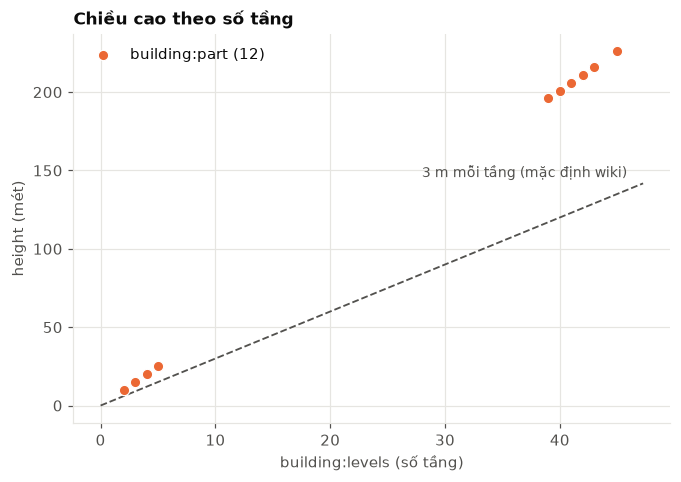

,way_id,kind,levels,height,m_per_level
5,1225581670,building:part,45.0,226.0,5.02
0,1225581665,building:part,43.0,216.0,5.02
6,1225581671,building:part,42.0,211.0,5.02
1,1225581666,building:part,42.0,211.0,5.02
2,1225581667,building:part,41.0,206.0,5.02
3,1225581668,building:part,40.0,201.0,5.03
4,1225581669,building:part,39.0,196.0,5.03
7,1225581672,building:part,5.0,25.0,5.00


In [20]:
both = []
for wid, w in ways.items():
    tags = w["tags"]
    if "building:levels" in tags and "height" in tags:
        both.append({
            "way_id": wid,
            "kind": "building" if "building" in tags else "building:part",
            "levels": to_number(tags["building:levels"]),
            "height": to_number(tags["height"]),
        })
both_df = pd.DataFrame(both).dropna()

fig, ax = plt.subplots(figsize=(7, 4.6))
for kind, color in (("building", BLUE), ("building:part", ORANGE)):
    sub = both_df[both_df["kind"] == kind]
    if sub.empty:
        continue
    ax.scatter(sub["levels"], sub["height"], s=46, color=color, edgecolors="white", linewidths=0.8, label=f"{kind} ({len(sub)})", zorder=3)
xs = np.array([0, both_df["levels"].max() * 1.05])
ax.plot(xs, 3 * xs, color=MUTED, linestyle="--", linewidth=1.2, zorder=2)
ax.text(xs[1] * 0.97, 3 * xs[1] + 4, "3 m mỗi tầng (mặc định wiki)", ha="right", color=MUTED, fontsize=9)
ax.set_xlabel("building:levels (số tầng)")
ax.set_ylabel("height (mét)")
ax.set_title("Chiều cao theo số tầng")
ax.legend(loc="upper left")
save(fig, "2_5_height_vs_levels.png")
plt.show()

both_df.assign(m_per_level=lambda d: (d["height"] / d["levels"]).round(2)).sort_values("height", ascending=False).head(8)

**Đọc kết quả:**
- Các building có số tầng thường tập trung ở 4 đến 5 tầng (nhà thấp) và 26 đến 31 tầng (chung cư).
- Chiều cao các tòa tháp (đoạn `building:part`) cao hơn đường mặc định 3 m mỗi tầng; khoảng 5 m mỗi tầng, nên khi dùng vào tính toán cần kiểm tra lại giá trị.
- Không building nào trong bảng `bh_df` có đồng thời cả hai tag; các điểm có cả hai nằm ở `building:part`.

## 6. Thống kê giá trị tag (cho báo cáo LT3)

Số liệu phục vụ `report/theory.md` mục LT3: các khóa `building`, `highway`, `layer`, `height`, `building:levels` và `level` (Simple Indoor Tagging) xuất hiện trên loại phần tử nào, với giá trị gì.

In [21]:
TAG_KEYS = ["building", "highway", "layer", "height", "building:levels", "bridge", "tunnel", "level", "entrance"]

presence = pd.DataFrame(
    {
        key: {
            "node": sum(1 for t in node_tags.values() if key in t),
            "way": sum(1 for w in ways.values() if key in w["tags"]),
            "relation": sum(1 for r in relations.values() if key in r["tags"]),
        }
        for key in TAG_KEYS
    }
).T
presence["tổng"] = presence.sum(axis=1)
presence

,node,way,relation,tổng
building,0,1371,2,1373
highway,879,1960,5,2844
layer,0,36,0,36
height,0,31,0,31
building:levels,0,117,0,117
bridge,0,19,0,19
tunnel,0,5,0,5
level,4,2,0,6
entrance,23,0,0,23


Xuất toàn bộ giá trị của các khóa trên (kèm `area` và các khóa Simple Indoor Tagging) ra `output/nb/tag_values.csv`: mỗi dòng là một cặp `(key, value)` và số lần xuất hiện, gộp cả node, way và relation.

In [22]:
VALUE_KEYS = TAG_KEYS + ["area", "indoor", "level:ref", "repeat_on", "door", "room", "buildingpart"]

value_counts = Counter()
for tags in [*node_tags.values(), *(w["tags"] for w in ways.values()), *(r["tags"] for r in relations.values())]:
    for key in VALUE_KEYS:
        if key in tags:
            value_counts[(key, tags[key])] += 1

tag_values_df = pd.DataFrame(
    [{"key": k, "value": v, "count": c} for (k, v), c in value_counts.items()]
).sort_values(["key", "count", "value"], ascending=[True, False, True]).reset_index(drop=True)
tag_values_df.to_csv(OUT / "tag_values.csv", index=False)
tag_values_df.head(10)

,key,value,count
0,area,yes,32
1,bridge,yes,19
2,building,yes,604
3,building,house,501
4,building,terrace,140
5,building,apartments,46
6,building,industrial,20
7,building,university,17
8,building,school,12
9,building,construction,11


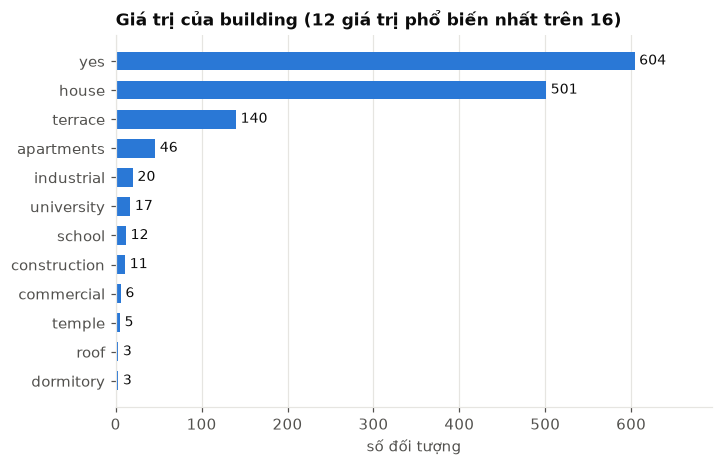

In [23]:
building_values = Counter(w["tags"]["building"] for w in ways.values() if "building" in w["tags"])
building_values.update(r["tags"]["building"] for r in relations.values() if "building" in r["tags"])
top_building = pd.Series(building_values).sort_values(ascending=False).head(12)[::-1]

fig, ax = plt.subplots(figsize=(7, 4.4))
bars = ax.barh(top_building.index, top_building.values, color=BLUE, height=0.65)
bar_labels(ax, bars, top_building.values)
ax.set_xlim(0, top_building.max() * 1.15)
ax.set_title(f"Giá trị của building (12 giá trị phổ biến nhất trên {len(building_values)})")
ax.set_xlabel("số đối tượng")
ax.grid(axis="y", visible=False)
save(fig, "6_building_values.png")
plt.show()

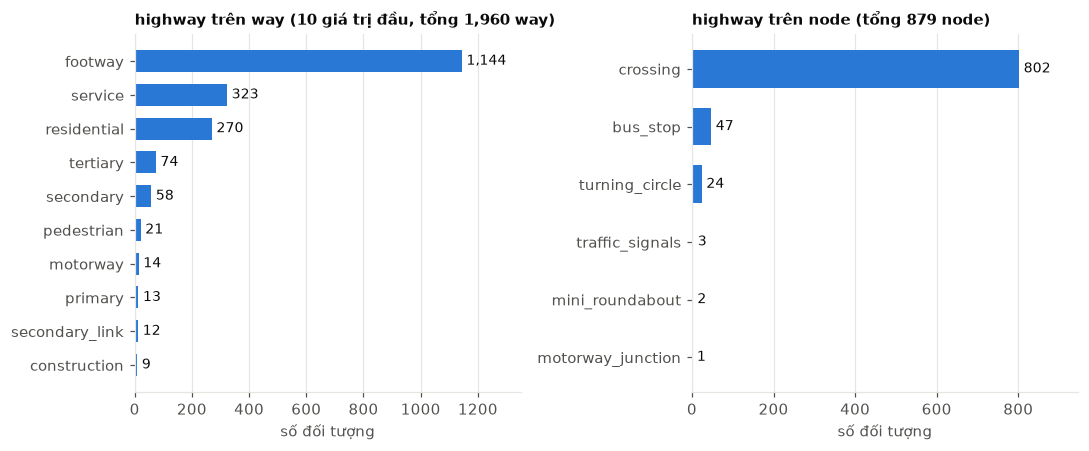

In [24]:
way_hw = pd.Series(Counter(w["tags"]["highway"] for w in highway_ways.values())).sort_values(ascending=False).head(10)[::-1]
node_hw = pd.Series(Counter(t["highway"] for t in node_tags.values() if "highway" in t)).sort_values(ascending=False)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, series, title in (
    (axes[0], way_hw, f"highway trên way (10 giá trị đầu, tổng {len(highway_ways):,} way)"),
    (axes[1], node_hw, f"highway trên node (tổng {node_hw.sum():,} node)"),
):
    bars = ax.barh(series.index, series.values, color=BLUE, height=0.65)
    bar_labels(ax, bars, series.values)
    ax.set_xlim(0, series.max() * 1.18)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("số đối tượng")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "6_highway_values.png")
plt.show()

**Đọc kết quả:** cùng khóa `highway` nhưng trên **way** là loại đường (đường đi bộ, đường nội khu, đường chính), còn trên **node** là tiện ích (vạch qua đường, trạm xe buýt). Vì vậy phần 2.2 chỉ xét way.

## 7. Tổng hợp

Bảng tổng hợp kết quả của các phần. Các file CSV do notebook tạo nằm trong `output/nb/`, hình nằm trong `output/figures/`.

In [25]:
results = pd.DataFrame([
    ("2.1", "Số node / way / relation", f"{len(nodes):,} / {len(ways):,} / {len(relations):,}"),
    ("2.2", "Node dùng chung từ 2 way highway", f"{len(shared_df):,}"),
    ("2.3", "Relation multipolygon có building", f"{len(mp_df)}"),
    ("2.4", "Way có layer, bridge hoặc tunnel", f"{len(lbt_df)}"),
    ("2.5", "Building có levels hoặc height", f"{len(bh_df)}"),
], columns=["phần", "nội dung", "kết quả"])
results

,phần,nội dung,kết quả
0,2.1,Số node / way / relation,"31,117 / 3,951 / 89"
1,2.2,Node dùng chung từ 2 way highway,"3,621"
2,2.3,Relation multipolygon có building,2
3,2.4,"Way có layer, bridge hoặc tunnel",36
4,2.5,Building có levels hoặc height,99
